# EDA: quentin_house building simulations

**Goal of this notebook:** understand the dataset before model design and training, and prepare the train/val/test split and the normalization statistics.

I want to answer four questions:
1. Is the data well formed (shapes, missing values, duplicates, constant signals)?
2. Do the target indicators (HLC, HLC_mit, HLC_ext, tau_b, tau_n, tau_inf) follow the physics I expect?
3. What do the input signals (indoor temperature and heating power) look like?
4. Where might the data be unusual, and how should that affect the split, the flags, and the evaluation?

**Conventions used throughout**
- HLC and H_b are in W/K. tau values are in hours.
- Temperatures are in degC and heating power in W.
- Each scenario has 480 time steps. The assessment does not state the step duration, but the reference paper simulates with a 1-minute step, and the PRBS durations in the `solicitation` table (in hours) match the lengths of the on/off blocks if one step is one minute. So I take **1 step = 1 minute, and one scenario = 8 hours**.
- Sections 3 to 8 use the full dataset. The flags (section 10) and the normalization statistics (section 11) are computed on the training split only.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from coenergy.util_assessement import load_simulation_data
from coenergy.preprocessing import Scalers

SEED = 67
torch.manual_seed(SEED)
np.random.seed(SEED)

# This notebook lives in notebooks/, so the project root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / 'data' / 'quentin_house'
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

print(f'torch {torch.__version__} | CUDA available: {torch.cuda.is_available()}')

torch 2.11.0+cu128 | CUDA available: True


## 2. Loading the data

I load the simulations and build two things:
- **X**: the two time series (indoor temperature and heating power).
- **y**: the six target indicators, in the order HLC, HLC_mit, HLC_ext, tau_b, tau_n, tau_inf.

Leading and trailing spaces in the labels are removed so that column names are safe to use.

The loader also returns a `solicitation` table (12 parameters describing how each heating signal was generated). It is not part of X or y, but section 9 uses it to explain the constant heating signals.

In [2]:
simulations = load_simulation_data(folder_path=DATA_DIR)

# Dynamic inputs (X): one row per scenario, 480 time steps each
temperature = simulations.indoor_temperature.round(decimals=2)  # indoor air temperature, degC
excitation = simulations.indoor_U.round(decimals=1)  # heating power, W

# Targets (y)
hb_labels = [lbl.strip() for lbl in simulations.Hb_labels]
cdt_labels = ['tau_b', 'tau_n', 'tau_inf']
target_labels = ['HLC'] + hb_labels + cdt_labels

targets = torch.cat([simulations.HLC.unsqueeze(1), simulations.Hb, simulations.CDT], dim=1)
targets_np = targets.numpy()

N, T = temperature.shape
print(f'Scenarios: {N:,} | time steps per scenario: {T}')
print(f'Targets shape: {tuple(targets.shape)} | labels: {target_labels}')
print(f'Inputs shape:  temperature {tuple(temperature.shape)}, excitation {tuple(excitation.shape)}')

assert temperature.shape == excitation.shape, 'Input series must have the same shape'
assert targets.shape[0] == N, 'Targets and inputs must have the same number of scenarios'

Scenarios: 1,000,000 | time steps per scenario: 480
Targets shape: (1000000, 6) | labels: ['HLC', 'HLC_mit', 'HLC_ext', 'tau_b', 'tau_n', 'tau_inf']
Inputs shape:  temperature (1000000, 480), excitation (1000000, 480)


In [3]:
print(simulations.solicitation_field_names)
print(simulations.solicitation.shape)

['max_power_wat', 'start_amplitude_wat', 'end_amplitude_wat', 'start_period_hours', 'end_period_hours', 'transition_speed', 'phase_shift', 'average_fluctuation_wat', 'prbs_min_duration_hours', 'prbs_max_duration_hours', 'prbs_probability_on', 'prbs_seed']
torch.Size([1000000, 12])


**Observations**

Each scenario was generated from a heating plan with 12 parameters. They are stored in the `solicitation` tensor, with shape `(1,000,000, 12)`, one row per scenario. The column names are in `solicitation_field_names`.

From the names, the generator can produce two kinds of signal:

- **Sinusoidal component** (amplitude and period, which change from start to end, with a transition speed and phase shift):
  `start_amplitude_wat`, `end_amplitude_wat`, `start_period_hours`, `end_period_hours`, `transition_speed`, `phase_shift`, `average_fluctuation_wat`
- **PRBS component** (a random on/off switch):
  `prbs_min_duration_hours`, `prbs_max_duration_hours`, `prbs_probability_on`, `prbs_seed`

`max_power_wat` is the heater power shared by both.

In this dataset only the **PRBS component** is used: all the sinusoidal parameters are 0 in every scenario (checked in section 9). These parameters describe how the heating was designed, but they are **not** model inputs in the assessment.

## 3. Data integrity

Before looking at the physics, I check that nothing is broken: no NaN or infinite values, no constant (flat) signals, and no duplicated scenarios.

A flat signal would mean a failed simulation or a heater that never switched on. Duplicate scenarios would make the test set look easier than it is if they leaked across splits.

In [4]:
arrays = {'temperature': temperature, 'excitation': excitation, 'targets': targets}
for name, arr in arrays.items():
    n_nan = torch.isnan(arr).sum().item()
    n_inf = torch.isinf(arr).sum().item()
    print(f'{name:12s} NaN: {n_nan:>6d} | Inf: {n_inf:>6d}')

temp_flat = (temperature.std(dim=1) == 0).sum().item()
exc_flat = (excitation.std(dim=1) == 0).sum().item()
print(f'Scenarios with a flat temperature series: {temp_flat}')
print(f'Scenarios with a flat excitation series:  {exc_flat}')

# Duplicate check on the target vectors 
n_unique = torch.unique(targets, dim=0).shape[0]
print(f'Unique target vectors: {n_unique:,} out of {N:,}')

temperature  NaN:      0 | Inf:      0


excitation   NaN:      0 | Inf:      0
targets      NaN:      0 | Inf:      0


Scenarios with a flat temperature series: 0
Scenarios with a flat excitation series:  92875


Unique target vectors: 1,000,000 out of 1,000,000


**Observations (section 3)**
- There are no NaN or infinite values in the inputs or the targets, so no imputation is needed.
- No scenario has a flat temperature series.
- 92,875 scenarios (9.3%) have a perfectly constant heating signal. Their temperature still changes, so these are not failed simulations. But the model never sees the heater switch on or off in them, so they contain much less information about the building.
- All 1,000,000 target vectors are unique, so there are no exact duplicate scenarios at the target level.

**Note:** the duplicate check uses the targets only. With continuous float targets, uniqueness is almost guaranteed, so this is a weak check.

## 4. Target statistics

A summary table of each target. The spread of the values matters for later: the time constants are much smaller in size than HLC, so an unscaled loss would mostly ignore them.

In [5]:
summary = pd.DataFrame(targets_np, columns=target_labels).describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T
summary.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max
HLC,1000000.0,232.93,31.33,111.40,166.46,210.65,231.80,254.13,307.91,368.00
HLC_mit,1000000.0,120.49,26.26,42.84,69.37,100.86,118.90,138.55,183.46,231.53
HLC_ext,1000000.0,112.44,17.11,52.65,75.65,100.27,112.19,124.26,152.25,185.89
tau_b,1000000.0,50.00,10.10,20.20,31.53,42.78,48.82,55.95,78.76,122.88
tau_n,1000000.0,11.04,2.01,5.17,7.40,9.61,10.79,12.20,16.83,25.84
tau_inf,1000000.0,31.23,7.53,10.48,18.08,25.83,30.20,35.52,53.38,93.12


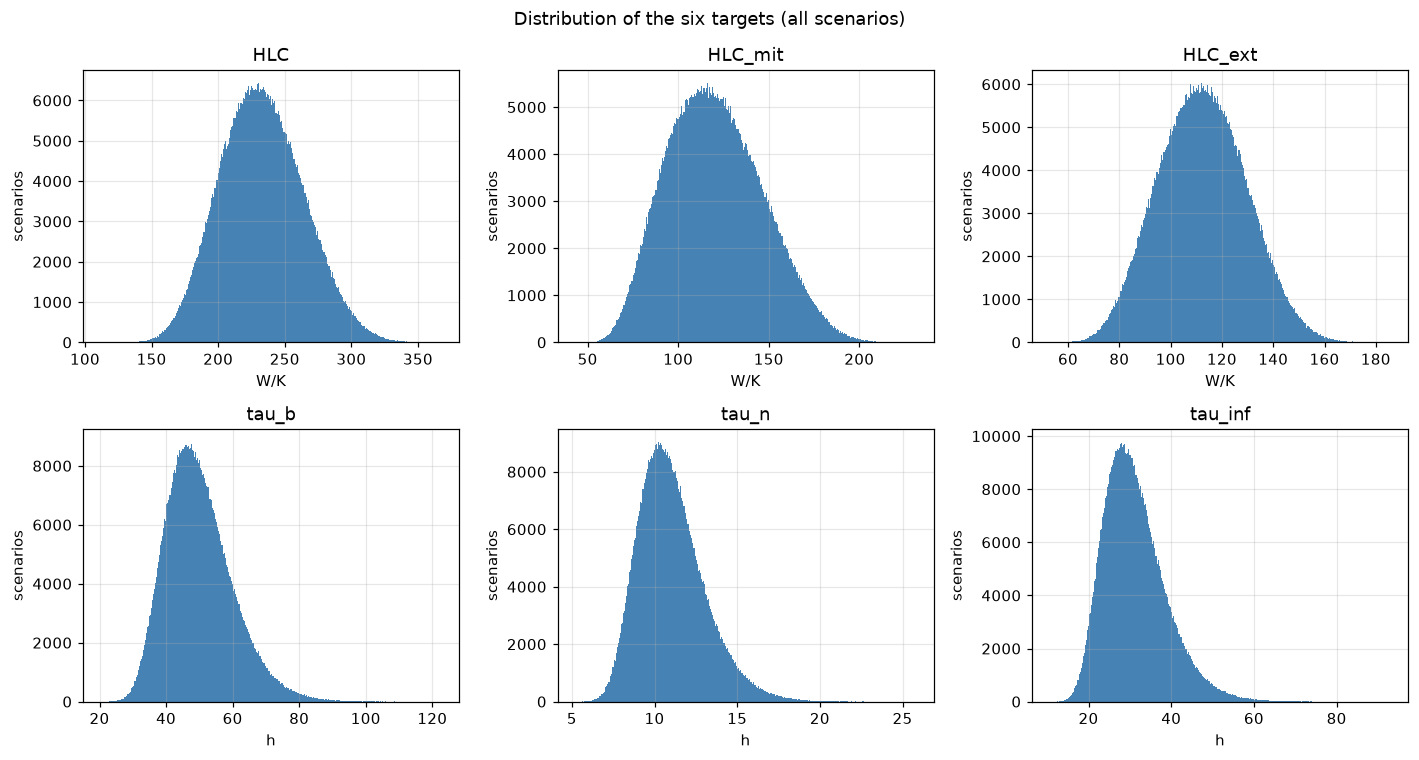

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, j in zip(axes.ravel(), range(len(target_labels))):
    ax.hist(targets_np[:, j], bins=500, color='steelblue', edgecolor='none')
    ax.set_title(target_labels[j])
    ax.set_xlabel('h' if target_labels[j].startswith('tau') else 'W/K')
    ax.set_ylabel('scenarios')
fig.suptitle('Distribution of the six targets (all scenarios)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'target_histograms.png', dpi=150)
plt.show()

**Observations (section 4)**
- **HLC** has a mean of about 233 W/K and a standard deviation of about 31 W/K. The histogram is bell-shaped and roughly symmetric. 98% of scenarios lie between 166 and 308 W/K (1st to 99th percentile). The extremes (111 and 368 W/K) are rare.
- **HLC_mit** (mean about 120 W/K) and **HLC_ext** (mean about 112 W/K) add up to HLC, so each is roughly half of it. HLC_mit varies more (std 26 W/K against 17 W/K).
- **tau_b** averages about 50 h, **tau_inf** about 31 h, and **tau_n** about 11 h. Unlike the HLC family, the three time constants are **right-skewed**: the mean is above the median, and there is a long tail on the right (tau_b goes up to 123 h while its 99th percentile is 79 h).
- The targets live on very different scales (HLC std about 31 W/K, tau_n std about 2 h), so each one needs its own scaling before training.


## 5. Physics checks on the targets

Two relationships should hold by definition:
1. **Sum rule:** HLC = HLC_mit + HLC_ext. I check the residual per scenario. Because I use 32-bit floats, a tiny residual is expected from rounding.
2. **Time constants:** the definitions suggest tau_b should be the longest, and all values should be positive. The assessment does not state an ordering between tau_inf and tau_n, so I report how often each relationship holds instead of treating a violation as an error.

Sum rule residual: max 3.052e-05 W/K | mean 4.481e-06 W/K
Scenarios with residual > 1e-3 W/K: 0 (0.00%)


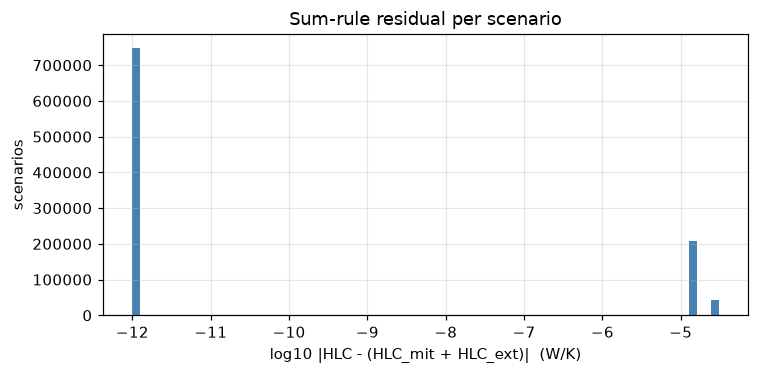

In [7]:
resid = (targets[:, 0] - (targets[:, 1] + targets[:, 2])).abs().numpy()

print(f'Sum rule residual: max {resid.max():.3e} W/K | mean {resid.mean():.3e} W/K')
print(f'Scenarios with residual > 1e-3 W/K: {(resid > 1e-3).sum():,} ({(resid > 1e-3).mean():.2%})')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(resid + 1e-12), bins=80, color='steelblue', edgecolor='none')
ax.set_xlabel('log10 |HLC - (HLC_mit + HLC_ext)|  (W/K)')
ax.set_ylabel('scenarios')
ax.set_title('Sum-rule residual per scenario')
fig.tight_layout()
plt.show()

In [8]:
tau_b, tau_n, tau_inf = targets[:, 3], targets[:, 4], targets[:, 5]

checks = {
    'tau_b > tau_inf': (tau_b > tau_inf).float().mean().item(),
    'tau_inf > tau_n': (tau_inf > tau_n).float().mean().item(),
    'all tau > 0': (targets[:, 3:] > 0).all(dim=1).float().mean().item(),
}
for label, share in checks.items():
    print(f'{label:18s}: {share:.2%} of scenarios')

tau_b > tau_inf   : 100.00% of scenarios
tau_inf > tau_n   : 100.00% of scenarios
all tau > 0       : 100.00% of scenarios


**Observations (section 5)**
- The sum rule holds for every scenario. The maximum residual is 3.05e-5 W/K and none is above 1e-3 W/K. The histogram has only three bars: about 750,000 scenarios with a residual of exactly 0 (plotted at -12 because of the 1e-12 offset), and the rest at about 1.5e-5 and 3e-5 W/K. These are one-step float32 rounding errors for numbers between 128 and 512, so the rule is exact by construction. I can enforce it in the model (predict HLC_mit and HLC_ext, then add them) instead of asking the network to learn it.
- All time constants are positive in 100% of scenarios.
- The ordering **tau_b > tau_inf > tau_n holds in 100% of scenarios**, not only on average. This fits the definitions: tau_inf is the limit of tau_n when the cooling lasts forever instead of 8 h, so it should be longer, and tau_b involves the whole building mass. Since the ordering never breaks, it could also be built into the model (for example, predict tau_n and two positive increments).

## 6. Target correlations

Correlations show which targets carry overlapping information. A very high correlation between two targets means a model may not need to predict both separately, and it means the errors on those targets are probably linked.

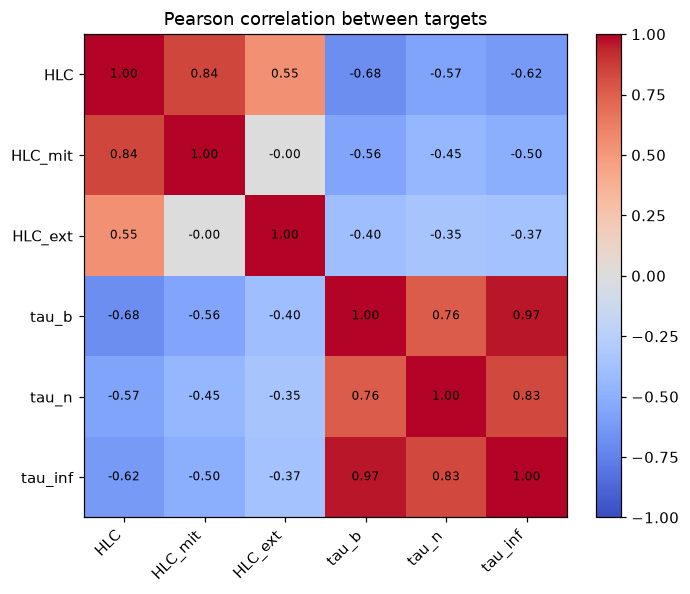

In [9]:
corr = torch.corrcoef(targets.T).numpy()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(target_labels)))
ax.set_xticklabels(target_labels, rotation=45, ha='right')
ax.set_yticks(range(len(target_labels)))
ax.set_yticklabels(target_labels)
for i in range(len(target_labels)):
    for j in range(len(target_labels)):
        ax.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title('Pearson correlation between targets')
fig.tight_layout()
fig.savefig(FIG_DIR / 'target_correlation.png', dpi=150)
plt.show()

**Observations (section 6)**
- HLC is strongly correlated with HLC_mit (0.84) and less with HLC_ext (0.55). This is expected because HLC is their sum, and HLC_mit has the larger variance, so it drives more of the variation in HLC.
- **HLC_mit and HLC_ext are uncorrelated (r = -0.00).** They look like they were sampled independently. Knowing one tells you nothing (linearly) about the other, so the model has to recover each one from the signals. It is not obvious that the split between outside and neighbouring losses can be read from indoor temperature and heating power alone (the nearest-neighbour test in section 8 looks at this).
- The three time constants are strongly correlated with each other: tau_b with tau_inf at 0.97, tau_inf with tau_n at 0.83, tau_b with tau_n at 0.76. tau_b and tau_inf carry almost the same linear information.
- The time constants are **negatively** correlated with HLC (-0.57 to -0.68). This matches the physics: a time constant is roughly heat capacity divided by heat loss (tau ≈ C / H), so a leakier building cools down faster and has shorter time constants.

**Note:** correlation only measures linear association. A value near zero does not mean two targets are unrelated.

## 7. Input signals

I summarize each scenario's input signals with a few numbers:
- **duty cycle:** fraction of time steps with heating on (power > 0).
- **max power:** largest heating power in the scenario.
- **pooled statistics:** printed in the second cell, over all scenarios and time steps.
- **temperature range:** max minus min indoor temperature within the scenario. This is a rough measure of how much the building responds.
- **mean temperature:** average indoor temperature, a rough measure of the operating level.

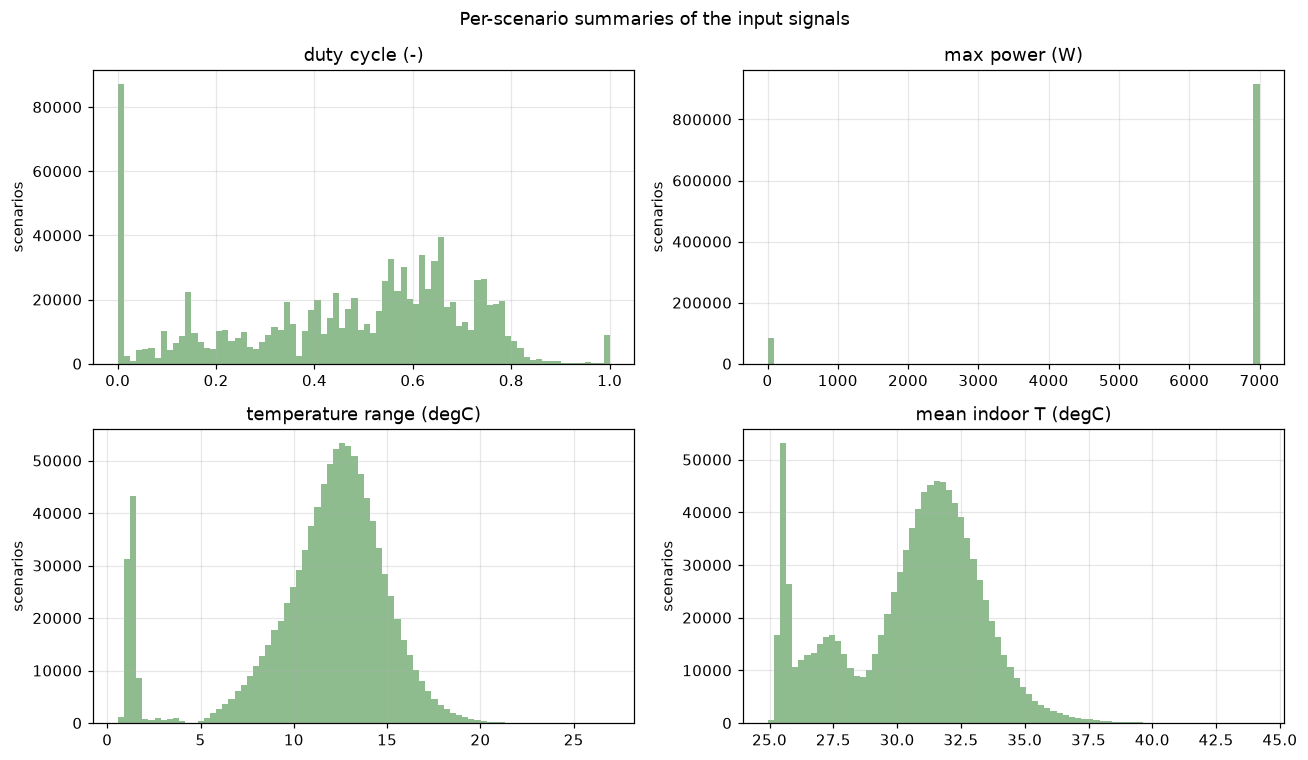

In [10]:
duty_cycle = (excitation > 0).float().mean(dim=1)
exc_max = excitation.max(dim=1).values
temp_mean_scn = temperature.mean(dim=1)
temp_range = temperature.max(dim=1).values - temperature.min(dim=1).values

features = {
    'duty cycle (-)': duty_cycle,
    'max power (W)': exc_max,
    'temperature range (degC)': temp_range,
    'mean indoor T (degC)': temp_mean_scn,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (name, values) in zip(axes.ravel(), features.items()):
    ax.hist(values.numpy(), bins=80, color='darkseagreen', edgecolor='none')
    ax.set_title(name)
    ax.set_ylabel('scenarios')
fig.suptitle('Per-scenario summaries of the input signals')
fig.tight_layout()
fig.savefig(FIG_DIR / 'input_summaries.png', dpi=150)
plt.show()

In [11]:
# Pooled statistics over all scenarios and time steps
print('distinct heating power values (W):', torch.unique(excitation).tolist())
print(f'heating power: mean {excitation.mean():.1f} W | std {excitation.std():.1f} W')
print(f'indoor T: min {temperature.min():.2f} | max {temperature.max():.2f} | '
      f'mean {temperature.mean():.2f} | std {temperature.std():.2f} degC')
print('distinct starting temperatures (degC):', torch.unique(temperature[:, 0]).tolist())
print(f'scenarios reaching 7000 W at least once: {(exc_max == 7000).float().mean():.2%}')
q = torch.tensor([0.1, 0.25, 0.5, 0.75, 0.9])
print('duty cycle quantiles (10/25/50/75/90%):', [round(v, 2) for v in torch.quantile(duty_cycle, q).tolist()])

distinct heating power values (W): [0.0, 7000.0]


heating power: mean 3280.7 W | std 3493.1 W


indoor T: min 24.22 | max 51.55 | mean 30.56 | std 4.79 degC
distinct starting temperatures (degC): [24.6200008392334]
scenarios reaching 7000 W at least once: 91.58%
duty cycle quantiles (10/25/50/75/90%): [0.06, 0.31, 0.54, 0.65, 0.75]


**Observations (section 7)**
- **Heating power is binary.** The only two values are 0 W and 7000 W. Pooled over all time steps, the mean (3281 W) and standard deviation (3493 W) are nearly equal, which is what an on/off signal that is on about half the time gives. 91.6% of scenarios reach 7000 W at some point; the remaining 8.4% are the never-heated scenarios found in section 3.
- **The duty cycle is spread over the whole range.** The median is 0.54, and the middle half of the scenarios lies between 0.31 and 0.65. The 10th percentile is 0.06: 10% of scenarios are heated at most 6% of the time. Most of these 10% are the 8.4% never-heated scenarios; the other 1.6% switch on briefly. The histogram has a spike at 0 (never heated, about 84,000 scenarios) and a small spike at 1 (always on, about 9,000).
- **Every scenario starts at exactly 24.62 degC.** Indoor temperature then stays between 24.22 and 51.55 degC (mean 30.56, std 4.79). The minimum is slightly below the start, so some scenarios cool a little at first.
- **Temperature range per scenario is bimodal.** A small group sits around 1 to 2 degC: these are the never-heated scenarios, where the temperature only drifts a little. The main group goes from about 5 to 20 degC with a peak around 12 to 13 degC.
- **Mean indoor temperature is also bimodal**, with a sharp spike around 25.5 degC (never-heated scenarios, close to the starting temperature) and a main mode around 31 to 32 degC, with a tail up to about 44 degC.
- The reference paper uses 45 degC as its safety limit for the heaters, so scenarios that go above this value are flagged in section 10.

**Why a 2000 W threshold is meaningless here:** the power is either 0 or 7000 W, so any threshold between them only separates "heated at some point" from "never heated". It cannot find unusual scenarios. The 7000 W level is a fixed generator setting (section 9), much higher than the two 2 kW heaters in the reference paper.

## 8. Inputs against targets

I look at a few example scenarios first, then at how the summary features relate to HLC.

I pick three scenarios: at the 5th percentile, median, and 95th percentile of HLC. This shows how the temperature response changes with the building's leakiness.

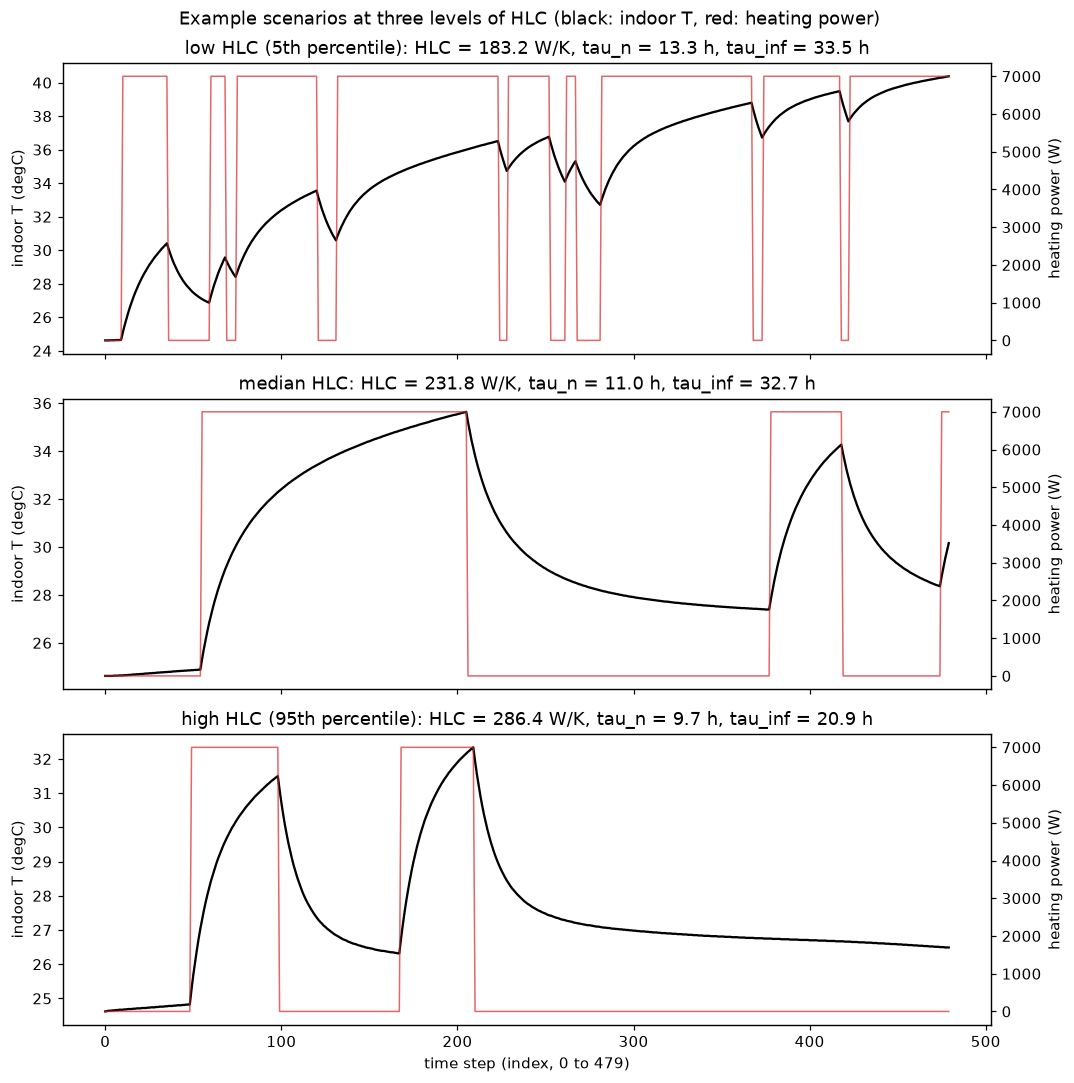

In [12]:
hlc = targets[:, 0]
ranks = torch.argsort(hlc)
picks = [
    ('low HLC (5th percentile)', int(ranks[int(0.05 * N)])),
    ('median HLC', int(ranks[N // 2])),
    ('high HLC (95th percentile)', int(ranks[int(0.95 * N)])),
]

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
t_axis = np.arange(T)
for ax, (name, idx) in zip(axes, picks):
    ax_p = ax.twinx()
    ax.plot(t_axis, temperature[idx].numpy(), color='black', lw=1.5)
    ax_p.plot(t_axis, excitation[idx].numpy(), color='tab:red', lw=1, alpha=0.7)
    ax.set_title(
        f'{name}: HLC = {hlc[idx]:.1f} W/K, tau_n = {targets[idx, 4]:.1f} h, tau_inf = {targets[idx, 5]:.1f} h'
    )
    ax.set_ylabel('indoor T (degC)')
    ax_p.set_ylabel('heating power (W)')
    ax.grid(False)
    ax_p.grid(False)
axes[-1].set_xlabel('time step (index, 0 to 479)')
fig.suptitle('Example scenarios at three levels of HLC (black: indoor T, red: heating power)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'example_trajectories.png', dpi=150)
plt.show()

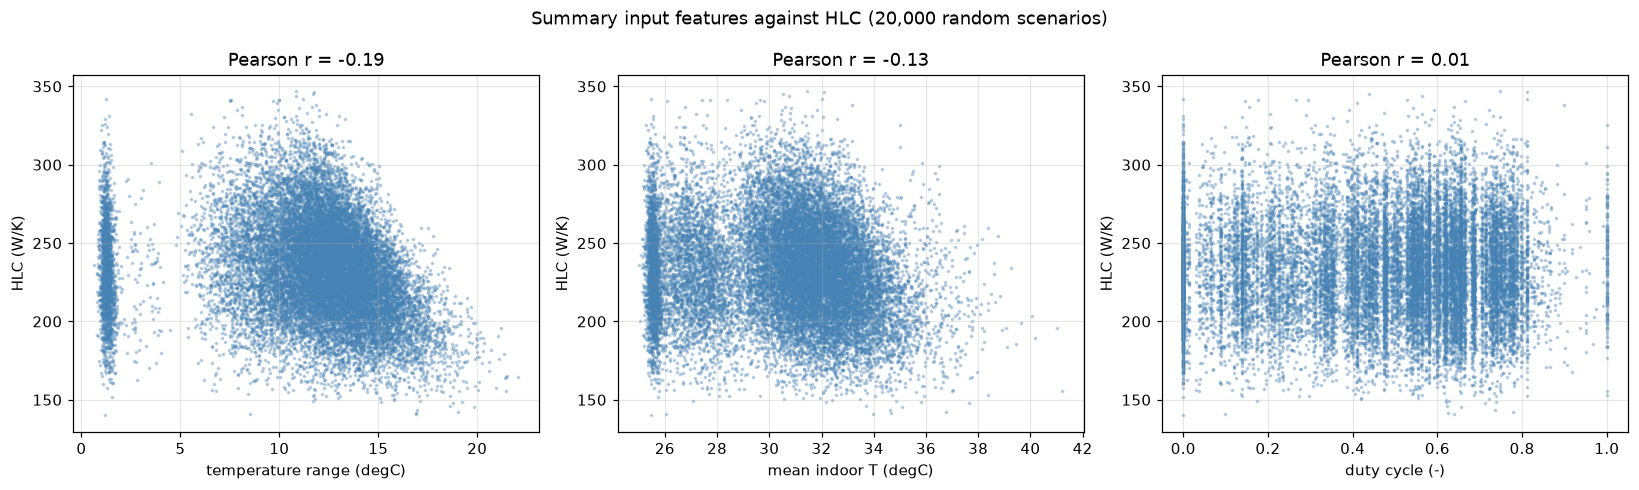

In [13]:
# Subsample for readable scatter plots
g = torch.Generator().manual_seed(SEED)
sub = torch.randperm(N, generator=g)[:20000]

pairs = [
    (temp_range, 'temperature range (degC)'),
    (temp_mean_scn, 'mean indoor T (degC)'),
    (duty_cycle, 'duty cycle (-)'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x, label) in zip(axes, pairs):
    xs = x[sub].numpy()
    ys = hlc[sub].numpy()
    ax.scatter(xs, ys, s=2, alpha=0.3, color='steelblue')
    ax.set_xlabel(label)
    ax.set_ylabel('HLC (W/K)')
    r = np.corrcoef(xs, ys)[0, 1]
    ax.set_title(f'Pearson r = {r:.2f}')
fig.suptitle('Summary input features against HLC (20,000 random scenarios)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'features_vs_hlc.png', dpi=150)
plt.show()

**Observations (section 8)**
- All three examples start at the same temperature (about 24.6 degC) and use the same heating level (7000 W). The low-HLC building reaches about 40 degC, the median one about 36 degC, and the high-HLC one only about 32 degC.
- **But these peaks mostly come from the heating schedules, not from HLC.** The low-HLC example is heated most of the time with short breaks, so heat builds up from one cycle to the next. The high-HLC example is only heated for two short periods and spends most of the window cooling down. With the same schedule, the high-HLC building would also get much warmer than 32 degC. So the figure cannot be used to compare the buildings directly.
- What HLC does change is the **shape** of the response under the same heating: a leakier building levels off at a lower temperature during long heating periods (temperature rise ≈ power / HLC at steady state) and cools down faster when the heater stops. A fast rise right after switch-on mostly means a small heat capacity, not a high HLC.
- When the heater switches off, the temperature first drops quickly and then slowly. There are two time scales: the air heats and cools fast, the walls slowly. The tau targets describe this slow part.
- Even before the heater first turns on, the temperature rises slightly. So the boundaries (outside and neighbouring spaces) are probably warmer than the starting 24.6 degC, or the simulation does not start from equilibrium.
- In the scatter plots, the duty cycle has no linear relation with HLC (r = 0.01). The heating schedule was chosen independently of the building, so this is expected. Mean heating power is not plotted: because the power is 0 or 7000 W, it is exactly 7000 × duty cycle and would give the same plot.
- Temperature range (r = -0.19) and mean indoor temperature (r = -0.13) have weak negative correlations: leakier buildings warm up a bit less. The separate cluster on the left of both plots (range around 1.5 degC, mean around 25.5 degC) is the never-heated scenarios, and it covers the whole HLC range.
- **Conclusion:** simple averages of the inputs say almost nothing about HLC. The information is in the shape of the response (how fast the temperature rises and falls after each switch), so the model needs the full time series.

### Can the inputs determine the targets? Nearest-neighbour test

If two scenarios get the same heating signal and produce nearly the same temperature curve, a model cannot tell them apart. If their targets still differ a lot, that error cannot be removed by any model: it is a ceiling set by the data.

Method:
1. Group scenarios that share exactly the same heating signal (same on/off sequence over the 480 steps).
2. Inside each group, find each scenario's nearest neighbour by temperature curve, excluding the scenario itself by index. Closeness is measured as the maximum absolute difference over all 480 steps (degC). The search uses the Euclidean distance to find 5 candidates quickly, then keeps the candidate with the smallest maximum difference.
3. For pairs whose curves are nearly identical, compare their targets.

Reference point: the same target gap for **random pairs** of scenarios. If near-identical curves have target gaps close to random pairs, the curves carry little information about the targets.

In [14]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Group scenarios by identical on/off heating pattern
keys = np.packbits((excitation > 0).numpy(), axis=1)  # 480 bits -> 60 bytes per scenario
_, group_id, group_size = np.unique(keys, axis=0, return_inverse=True, return_counts=True)
group_id = group_id.reshape(-1)
print(f'distinct heating signals: {len(group_size):,} | largest groups: {sorted(group_size.tolist(), reverse=True)[:5]}')
print(f'scenarios sharing their heating signal with at least one other: {(group_size[group_id] >= 2).sum():,}')

# 2. Nearest neighbour by temperature curve inside each group (self excluded by index)
nn_idx = torch.full((N,), -1, dtype=torch.long)
nn_dist = torch.full((N,), float('inf'))
order = np.argsort(group_id, kind='stable')
bounds = np.cumsum(group_size)[:-1]
for members in np.split(order, bounds):
    if len(members) < 2:
        continue
    members = torch.from_numpy(members)
    G = temperature[members].to(device)
    for start in range(0, len(members), 2048):
        q = G[start:start + 2048]
        rows = torch.arange(len(q), device=device)
        dist = torch.cdist(q, G)
        dist[rows, rows + start] = float('inf')                          # exclude the scenario itself
        cand = dist.topk(min(5, len(members) - 1), largest=False).indices  # 5 Euclidean candidates
        maxabs = (q.unsqueeze(1) - G[cand]).abs().amax(dim=2)              # max abs difference, degC
        best = maxabs.argmin(dim=1)
        sl = members[start:start + len(q)]
        nn_idx[sl] = members[cand[rows, best].cpu()]
        nn_dist[sl] = maxabs[rows, best].cpu()
    del G

# 3. Target gaps: nearest neighbours vs random pairs
has_nn = nn_idx >= 0
gap_nn = (targets[has_nn] - targets[nn_idx[has_nn]]).abs()
gap_random = (targets - targets[torch.randperm(N, generator=torch.Generator().manual_seed(SEED))]).abs()

kind = np.select([(excitation == 0).all(dim=1).numpy(), (excitation == 7000).all(dim=1).numpy()],
                 ['never heated', 'always on'], default='switching')[has_nn.numpy()]
d = nn_dist[has_nn]
rows = []
for name in ['never heated', 'always on', 'switching']:
    m = torch.from_numpy(kind == name)
    for thr in [0.02, 0.05, 0.10]:
        mm = m & (d <= thr)
        med = gap_nn[mm].median(dim=0).values if mm.any() else torch.full((6,), float('nan'))
        rows.append({'group': name, 'curves within (degC)': thr, 'pairs': int(mm.sum()),
                     **{f'{l} gap': v for l, v in zip(target_labels, med.tolist())}})
rows.append({'group': 'random pairs', 'curves within (degC)': np.nan, 'pairs': N,
             **{f'{l} gap': v for l, v in zip(target_labels, gap_random.median(dim=0).values.tolist())}})
ceiling = pd.DataFrame(rows).set_index(['group', 'curves within (degC)'])
print('\nMedian absolute target gap (W/K for HLC family, h for tau):')
ceiling.round(2)

distinct heating signals: 2,798 | largest groups: [84164, 14670, 14600, 8850, 8818]
scenarios sharing their heating signal with at least one other: 999,959



Median absolute target gap (W/K for HLC family, h for tau):


pairs  HLC gap  HLC_mit gap  HLC_ext gap  \
group        curves within (degC)                                               
never heated 0.02                      150    27.31        22.65        13.12   
             0.05                    59672    28.68        24.38        14.53   
             0.10                    84095    28.68        24.33        14.75   
always on    0.02                        0      NaN          NaN          NaN   
             0.05                      661    24.16        23.47        13.08   
             0.10                     6849    23.26        21.52        14.48   
switching    0.02                        2   105.82        83.93        21.89   
             0.05                    12152    24.76        22.84        14.60   
             0.10                   292392    24.29        22.29        15.21   
random pairs NaN                   1000000    30.16        25.48        16.62   

                                   tau_b gap  tau_n gap  tau_inf gap  
group        curves within (degC)                                     
never heated 0.02                       7.63       1.62         5.69  
             0.05                       8.66       1.65         6.32  
             0.10                       8.69       1.65         6.33  
always on    0.02                        NaN        NaN          NaN  
             0.05                       9.56       1.70         7.07  
             0.10                       9.23       1.64         6.65  
switching    0.02                      28.11       5.28        19.95  
             0.05                       8.85       1.65         6.60  
             0.10                       9.01       1.68         6.69  
random pairs NaN                        9.22       1.82         6.75

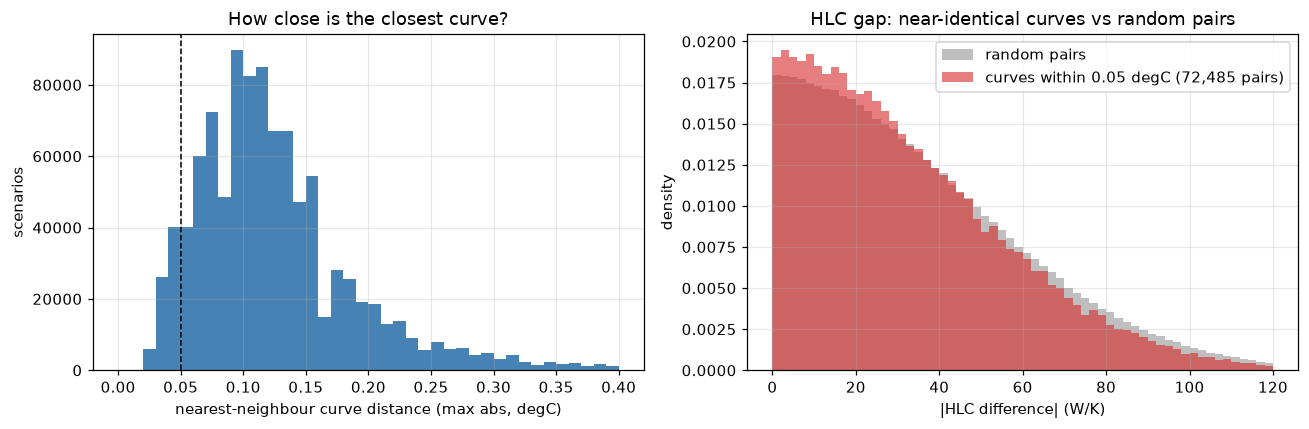

In [15]:
close = d <= 0.05
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(d.numpy(), bins=np.arange(0, 0.41, 0.01), color='steelblue', edgecolor='none')
axes[0].axvline(0.05, color='black', ls='--', lw=1)
axes[0].set_xlabel('nearest-neighbour curve distance (max abs, degC)')
axes[0].set_ylabel('scenarios')
axes[0].set_title('How close is the closest curve?')

bins = np.linspace(0, 120, 61)
axes[1].hist(gap_random[:, 0].numpy(), bins=bins, density=True, alpha=0.5, color='gray', label='random pairs')
axes[1].hist(gap_nn[close, 0].numpy(), bins=bins, density=True, alpha=0.6, color='tab:red',
             label=f'curves within 0.05 degC ({int(close.sum()):,} pairs)')
axes[1].set_xlabel('|HLC difference| (W/K)')
axes[1].set_ylabel('density')
axes[1].set_title('HLC gap: near-identical curves vs random pairs')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'ceiling_test.png', dpi=150)
plt.show()

del gap_nn, gap_random, nn_idx, nn_dist, keys, order

**Observations (nearest-neighbour test)**
- There are only **2,798 distinct heating signals** for 1,000,000 scenarios. All but 41 scenarios share their exact on/off sequence with at least one other scenario, so the test covers almost the whole dataset.
- The closest curve with the same heating is usually 0.05 to 0.15 degC away at its worst minute (left plot). No two scenarios have exactly the same curve. The comb shape of the histogram comes from rounding the temperature to 0.01 degC.
- **72,485 pairs have curves that stay within 0.05 degC of each other for all 480 minutes.** Yet their median HLC gap is 24 to 29 W/K, against 30 W/K for two random scenarios. In the right plot, the two distributions almost overlap.
- The other targets behave the same way. At 0.05 degC, the gaps are 23 to 24 W/K for HLC_mit (random: 25.5), 13 to 15 W/K for HLC_ext (random: 16.6), and 1.65 to 1.70 h for tau_n (random: 1.82). For **tau_b** (8.7 to 9.6 h against 9.2 h for random pairs) and **tau_inf** (6.3 to 7.1 h against 6.8 h), near-identical curves are barely closer than random pairs.
- The two switching pairs within 0.02 degC differ by 106 W/K in HLC (median). Two pairs are too few to conclude anything on their own, but they point the same way.

**Interpretation**
- Very similar inputs do not mean similar targets. A large part of the target variation is not visible in indoor temperature and heating power at this resolution. **This is a ceiling set by the data, not by the model:** no architecture can separate scenarios whose inputs are the same.
- It is not an exact bound. A model can still use differences smaller than 0.05 degC that are consistent over many steps (for example a small but steady difference in slope). So some skill is possible, but a near-perfect R² is not a realistic goal.
- The time constants, especially tau_b (about 50 h), are the least visible. An 8-hour window cannot show a 50-hour decay.
- The likely cause is something that varies between scenarios but is not part of X: boundary conditions (outdoor and neighbouring temperatures) or the initial temperature inside the walls. The reference paper randomizes the initial wall temperatures on purpose. This is a question for coEnergy.
- **Consequence for modeling:** model errors should be judged against this limit, not against zero, and per target family. Gains from bigger models will be small.

## 9. Train / validation / test split

I split by scenario because each scenario is one independent simulation. A 70 / 15 / 15 split is made with a fixed seed. The indices are saved, so the same split can be reloaded later.

**Note:** the heating schedules are shared between many scenarios (2,798 distinct schedules, section 8), so almost every schedule in the test set also appears in training. The test score therefore measures "new building, known schedule". To measure "new building, new schedule", the split would have to be made by schedule, keeping some schedules out of training completely.

In [16]:
gen = torch.Generator().manual_seed(SEED)
perm = torch.randperm(N, generator=gen)

n_train = int(0.70 * N)
n_val = int(0.15 * N)

train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

# The three sets must be disjoint and together cover every scenario
all_idx = torch.cat([train_idx, val_idx, test_idx])
assert all_idx.numel() == N, 'Splits do not cover the dataset'
assert torch.unique(all_idx).numel() == N, 'Splits overlap'

print(f'Total: {N:,} | train: {len(train_idx):,} | val: {len(val_idx):,} | test: {len(test_idx):,}')

SPLIT_PATH = PROJECT_ROOT / 'data' / 'splits' / 'split_70_15_15_seed67.pt'
SPLIT_PATH.parent.mkdir(parents=True, exist_ok=True)
torch.save({'train': train_idx, 'val': val_idx, 'test': test_idx, 'seed': SEED}, SPLIT_PATH)
print(f'Split indices saved to {SPLIT_PATH}')

Total: 1,000,000 | train: 700,000 | val: 150,000 | test: 150,000
Split indices saved to C:\Users\Youssef\Desktop\coenergy-assessment\data\splits\split_70_15_15_seed67.pt


### Closer look at the constant heating signals

Section 3 found 92,875 scenarios with a constant heating signal. The next cell checks which constant values they have, whether rounding hides near-flat signals, and whether the random split spread them evenly.

In [17]:
flat_mask = excitation.std(dim=1) == 0
print("flat scenarios:", flat_mask.sum().item())
vals, counts = torch.unique(excitation[flat_mask, 0], return_counts=True)
print("constant value(s) and counts:", list(zip(vals.tolist(), counts.tolist())))

# Near-flat: rounding to 0.1 W can hide tiny variations
span = excitation.max(dim=1).values - excitation.min(dim=1).values
print("span < 1 W:", (span < 1).sum().item())

# Are they spread evenly across splits? (should be ~9.3% of each)
for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(name, f"{flat_mask[idx].float().mean():.2%}")

# Temperature in these scenarios
print("flat temperature too:", (temperature[flat_mask].std(dim=1) == 0).sum().item())

flat scenarios: 92875
constant value(s) and counts: [(0.0, 84164), (7000.0, 8711)]
span < 1 W: 92875
train 9.29%
val 9.23%
test 9.32%


flat temperature too: 0


**Observations (constant heating signals)**
- The 92,875 constant signals are of two kinds: **84,164 never heated (0 W)** and **8,711 always on (7000 W)**.
- The count with a span below 1 W is the same (92,875), so rounding to 0.1 W does not hide any near-flat signals.
- They are spread evenly over the splits (9.29% train, 9.23% val, 9.32% test), so the random split does not need stratification for them.
- None of them has a flat temperature series. The building still responds, so these are valid simulations. But they are probably the hardest cases for the model.

### The `solicitation` table: how the heating signals were generated

The loader returns 12 parameters per scenario that describe the heating-signal generator. They are not model inputs, but they can explain the constant heating signals found above.

In [18]:
sol = pd.DataFrame(simulations.solicitation.numpy(), columns=simulations.solicitation_field_names)

n_distinct = sol.nunique()
print('Columns with a single value in all scenarios:')
print(sol.loc[0, n_distinct == 1].to_string())

prbs_cols = list(n_distinct[n_distinct > 1].index)
print('\nColumns that vary:', prbs_cols)

heating_group = np.select(
    [(excitation == 0).all(dim=1).numpy(), (excitation == 7000).all(dim=1).numpy()],
    ['never heated', 'always on'],
    default='switching',
)
sol[prbs_cols].groupby(heating_group).describe(percentiles=[0.5]).T.round(3)

Columns with a single value in all scenarios:


max_power_wat              7000.0
start_amplitude_wat           0.0
end_amplitude_wat             0.0
start_period_hours            0.0
end_period_hours              0.0
transition_speed             14.0
phase_shift                   0.0
average_fluctuation_wat       0.0
prbs_seed                    42.0

Columns that vary: ['prbs_min_duration_hours', 'prbs_max_duration_hours', 'prbs_probability_on']


always on  never heated   switching
prbs_min_duration_hours count   8711.000     84164.000  907125.000
                        mean       1.648         1.351       0.962
                        std        0.207         0.465       0.575
                        min        1.183         0.433       0.000
                        50%        1.651         1.469       0.950
                        max        2.000         2.000       2.000
prbs_max_duration_hours count   8711.000     84164.000  907125.000
                        mean       3.297         2.702       1.924
                        std        0.415         0.930       1.150
                        min        2.367         0.867       0.000
                        50%        3.302         2.938       1.901
                        max        4.000         4.000       4.000
prbs_probability_on     count   8711.000     84164.000  907125.000
                        mean       0.891         0.251       0.574
                        std        0.005         0.045       0.187
                        min        0.882         0.200       0.200
                        50%        0.891         0.238       0.576
                        max        0.900         0.383       0.900

**Observations (solicitation table)**
- 9 of the 12 parameters are the same in every scenario. In particular `max_power_wat` (7000 W) is the configured heater power. The amplitude, period and fluctuation parameters are all 0, so only the pseudo-random on/off part (PRBS) of the generator is used. `prbs_seed` is 42 in every scenario.
- Only 3 parameters vary: the minimum and maximum duration of an on/off segment, and the probability of being on. In every group the maximum duration is about twice the minimum.
- **The constant signals are explained by these parameters.** Never-heated scenarios have a low probability of being on (0.20 to 0.38, median 0.24) and longer segments (median minimum duration 1.47 against 0.95 for switching scenarios). Always-on scenarios have a very high probability (0.88 to 0.90) and long segments as well. With long segments and an extreme probability, the window of 480 steps can end before the first switch.
- So these scenarios are a side effect of how the heating signals were generated, not failed simulations. Whether they are useful training data is still a question for coEnergy.

## 10. Flags on the training split

I flag scenarios that look unusual, using the training split only:
- **hot:** the indoor temperature goes above 45 degC at some point. This is the reference paper's safety limit for the heaters. 
- **high HLC:** HLC above 300 W/K. This is a threshold I chose: it is roughly the top 2% of the distribution (the 99th percentile of HLC is 308 W/K).
- **constant heating:** the heating signal never switches (never heated or always on).

**Flagged scenarios are kept in the data.** They are useful as separate subsets in the error analysis, so I can see whether the model is weaker on them. Deleting them would hide that weakness.

paper: [Building-specific excitation optimization and simulation-driven machine learning for rapid in situ identification of the heat loss coefficient](../ssrn-6928008.pdf)

In [19]:
tr = train_idx
temp_max_train = temperature[tr].max(dim=1).values  # one value per scenario
hlc_train = targets[tr, 0]
exc_train = excitation[tr]

flag_hot = temp_max_train > 45.0
flag_high_hlc = hlc_train > 300.0
flag_const = exc_train.std(dim=1) == 0  # never heated or always on
flag_any = flag_hot | flag_high_hlc | flag_const

print(f'Training scenarios: {len(tr):,}')
print(f'Max temperature above 45 degC: {flag_hot.sum().item():,} ({flag_hot.float().mean():.2%})')
print(f'HLC above 300 W/K:             {flag_high_hlc.sum().item():,} ({flag_high_hlc.float().mean():.2%})')
print(f'Constant heating signal:       {flag_const.sum().item():,} ({flag_const.float().mean():.2%})')
print(f'Any flag:                      {flag_any.sum().item():,} ({flag_any.float().mean():.2%})')
print(f'hot & high HLC:                {(flag_hot & flag_high_hlc).sum().item():,}')
print(f'hot & constant:                {(flag_hot & flag_const).sum().item():,}')
print(f'high HLC & constant:           {(flag_high_hlc & flag_const).sum().item():,}')

Training scenarios: 700,000
Max temperature above 45 degC: 556 (0.08%)
HLC above 300 W/K:             13,562 (1.94%)
Constant heating signal:       65,053 (9.29%)
Any flag:                      77,907 (11.13%)
hot & high HLC:                0
hot & constant:                59
high HLC & constant:           1,205


**Observations (section 10)**
- 556 training scenarios (0.08%) go above 45 degC, 13,562 (1.94%) have HLC above 300 W/K, and 65,053 (9.29%) have a constant heating signal. 77,907 (11.13%) have at least one flag.
- **No scenario is both hot and high-HLC.** This is physical: for the same heating power, a leakier building reaches lower temperatures, so the very hot scenarios are low-HLC buildings.
- 59 hot scenarios also have constant heating. These are always-on scenarios: with the heater at 7000 W for the whole window, the temperature keeps rising.
- 1,205 high-HLC scenarios have constant heating, about 9% of them, which is the same rate as in the whole dataset. So the constant signals do not depend on the building.
- The hot subset is very small. With the same rate, the test split would contain only about 120 hot scenarios, so error metrics on that subset will be noisy.
- The high-HLC flag is based on a chosen threshold. It is a reasonable way to find the tail, but it is not a physical limit, and its meaning depends on the building population that coEnergy intended.

## 11. Normalization

I now prepare the inputs and targets for training. Every statistic is fitted on the **training split only** and then applied to the validation and test splits. Fitting on all data would leak information from evaluation into training.

**Strategy**
- **Indoor temperature:** global z-score, using the training mean and standard deviation. The values stay between about 24 and 52 degC, so one global scale is enough.
- **Heating power:** divide by the training maximum (7000 W). Because the power is either 0 or 7000 W, the scaled signal is exactly 0 or 1. Zero stays zero, which matters because "heater off" has a physical meaning. A z-score would shift zero to a non-zero value.
- **Targets:** z-score each column separately. The standard deviations differ by about a factor of 15 between HLC (31 W/K) and tau_n (2 h), so without this the loss would mostly ignore the time constants.
- **Inverse transform:** I keep the means and standard deviations so predictions can be converted back to W/K and hours for reporting.

The code lives in `src/coenergy/preprocessing.py` (class `Scalers`), so training and inference use the same functions as this notebook.

**Alternative to test later:** every scenario starts at the same temperature (24.62 degC), so subtracting the first time step would only shift all series by the same constant and would not change anything after the z-score. A more useful variant is to add the temperature change between steps (dT/dt) as an extra input channel, since the response speed is what carries the information about the building. This is what the model does (`CNNGRU` in `src/coenergy/models.py`).

In [20]:
# Fit normalization statistics on the TRAINING split only
scalers = Scalers.fit(
    temperature[train_idx], excitation[train_idx], targets[train_idx],
    target_labels=target_labels, seed=SEED,
)

print(f"temperature: mean {scalers.temp_mean:.3f} degC, std {scalers.temp_std:.3f} degC")
print(f"excitation scale (train max): {scalers.exc_scale:.1f} W")
for lbl, m, s in zip(target_labels, scalers.tgt_mean.tolist(), scalers.tgt_std.tolist()):
    print(f"{lbl:8s} mean {m:9.3f} | std {s:8.3f}")

temperature: mean 30.560 degC, std 4.788 degC
excitation scale (train max): 7000.0 W
HLC      mean   232.909 | std   31.321
HLC_mit  mean   120.468 | std   26.252
HLC_ext  mean   112.441 | std   17.114
tau_b    mean    50.003 | std   10.089
tau_n    mean    11.039 | std    2.008
tau_inf  mean    31.231 | std    7.525


### Checks on the normalized data

I check three things, using the `Scalers` methods:
1. The training split has mean close to 0 and std close to 1. Validation and test should be close to these values, but not exactly, since they were not used for fitting.
2. Targets survive a round trip: normalizing and then denormalizing gives back the original values.
3. Zero heating power is still zero after scaling.

In [21]:
def describe_split(name, idx):
    t = scalers.norm_temperature(temperature[idx])
    u = scalers.norm_excitation(excitation[idx])
    z = scalers.norm_targets(targets[idx])
    print(f"--- {name} ---")
    print(f"temperature  mean {t.mean():+.3f}  std {t.std():.3f}")
    print(f"excitation   min {u.min():.3f}  max {u.max():.3f}")
    print(f"targets mean per column: {[round(v, 3) for v in z.mean(dim=0).tolist()]}")
    print(f"targets std  per column: {[round(v, 3) for v in z.std(dim=0).tolist()]}")

describe_split("train", train_idx)
describe_split("val", val_idx)
describe_split("test", test_idx)

# Round trip
sample = targets[val_idx[:1000]]
err = (scalers.denorm_targets(scalers.norm_targets(sample)) - sample).abs().max().item()
print(f"\nRound-trip max abs error on targets: {err:.2e}")

# Zero heating stays zero
print("norm_excitation(0) =", scalers.norm_excitation(torch.tensor(0.0)).item())

--- train ---
temperature  mean +0.000  std 1.000


excitation   min 0.000  max 1.000
targets mean per column: [0.0, 0.0, -0.0, 0.0, 0.0, -0.0]
targets std  per column: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
--- val ---
temperature  mean +0.003  std 1.001


excitation   min 0.000  max 1.000
targets mean per column: [0.004, 0.003, 0.002, -0.003, -0.001, -0.002]
targets std  per column: [1.001, 1.0, 1.001, 1.001, 0.998, 1.0]
--- test ---
temperature  mean +0.000  std 1.001


excitation   min 0.000  max 1.000
targets mean per column: [-0.0, 0.002, -0.003, 0.002, 0.002, 0.002]
targets std  per column: [1.001, 1.001, 0.998, 1.004, 1.005, 1.004]

Round-trip max abs error on targets: 3.81e-06
norm_excitation(0) = 0.0


**Observations (section 11)**
- On the training split, temperature has mean 0.000 and std 1.000, and every target column has mean 0.0 and std 1.0. The fitting code works.
- On validation and test, the means stay within ±0.004 and the standard deviations between 0.998 and 1.005. The three splits come from the same distribution.
- Scaled heating power is exactly in [0, 1] in all three splits, because 7000 W is also the maximum in validation and test. If a future dataset had a larger power, the scaled values would go above 1. I would not clip them: a value above 1 is information, and clipping would hide it.
- The round trip recovers the targets with a maximum error of 3.8e-6, which is float32 precision. Predictions can be reported in physical units.

**The sum rule is not preserved by z-scoring.** Each target column has its own mean and standard deviation, so HLC, HLC_mit, and HLC_ext no longer add up in normalized space. The next cell shows it: on the validation split the mean gap is 0.389 in normalized units, but only 3.05e-5 W/K at most after converting back. If the model predicts normalized values, the sum rule must be enforced in physical units: predict HLC_mit and HLC_ext (positive, for example with softplus), convert them back to W/K, and add them to get HLC.

In [22]:
# Demonstrate that the sum rule breaks in normalized space but holds in physical units
z_val = scalers.norm_targets(targets[val_idx])
gap_z = (z_val[:, 0] - (z_val[:, 1] + z_val[:, 2])).abs().mean().item()

phys = scalers.denorm_targets(z_val)
gap_phys = (phys[:, 0] - (phys[:, 1] + phys[:, 2])).abs().max().item()

print(f"Normalized space: mean |HLC - (mit + ext)| = {gap_z:.3f}  (not zero)")
print(f"Physical units:   max  |HLC - (mit + ext)| = {gap_phys:.2e} W/K  (zero up to float precision)")

Normalized space: mean |HLC - (mit + ext)| = 0.389  (not zero)
Physical units:   max  |HLC - (mit + ext)| = 3.05e-05 W/K  (zero up to float precision)


## 12. Save the scalers

The scalers are saved next to the split indices, so training and inference use exactly the same preprocessing. They are saved as a plain dict, and `Scalers.load` rebuilds the object. Reloading is checked below.

In [23]:
SCALER_PATH = PROJECT_ROOT / 'data' / 'splits' / f'scalers_seed{SEED}.pt'
scalers.save(SCALER_PATH)

reloaded = Scalers.load(SCALER_PATH)
assert reloaded.temp_mean == scalers.temp_mean and reloaded.exc_scale == scalers.exc_scale
assert torch.equal(reloaded.tgt_mean, scalers.tgt_mean) and torch.equal(reloaded.tgt_std, scalers.tgt_std)
print(f"Scalers saved and verified: {SCALER_PATH}")


Scalers saved and verified: C:\Users\Youssef\Desktop\coenergy-assessment\data\splits\scalers_seed67.pt


## 13. Summary

**Findings**
1. No NaN or infinite values, no flat temperature series, and no duplicate target vectors. **But 92,875 scenarios (9.3%) have a constant heating signal:** 84,164 are never heated and 8,711 are heated the whole time. The `solicitation` table shows they come from the signal generator (low or very high probability of being on, with long segments), not from failed simulations.
2. The sum rule HLC = HLC_mit + HLC_ext holds exactly (maximum residual 3e-5 W/K, which is float32 rounding). Z-scoring breaks it, so it must be enforced in physical units.
3. All time constants are positive, and tau_b > tau_inf > tau_n in every scenario.
4. The HLC family is roughly bell-shaped. The time constants are right-skewed. All targets are on very different scales, so each one is standardized separately.
5. HLC_mit and HLC_ext are uncorrelated (r ≈ 0). The time constants are strongly correlated with each other (tau_b and tau_inf: 0.97) and negatively correlated with HLC (-0.57 to -0.68), as expected from tau ≈ C / H.
6. Heating power is binary (0 or 7000 W, a fixed generator setting), generated by a PRBS with only 2,798 distinct schedules. One step is one minute, so each scenario covers 8 hours. Every scenario starts at 24.62 degC. The duty cycle covers the full range from 0 to 1, with median 0.54. A 2 kW threshold is not meaningful for this data.
7. Simple input summaries (duty cycle, temperature range, mean temperature) have weak linear correlations with HLC (|r| ≤ 0.19). The model needs the time series dynamics.
8. In training, 556 scenarios go above 45 degC, 13,562 have HLC above 300 W/K, and 65,053 have constant heating. They are flagged, not removed.
9. **The inputs only partly determine the targets.** Scenarios with the same heating and temperature curves within 0.05 degC for 8 hours still differ by 24 to 29 W/K in HLC (median), close to the 30 W/K of random pairs. For tau_b and tau_inf, near-identical curves are barely closer than random pairs. Model errors must be judged against this data ceiling.
10. Normalization is fitted on the training split only, with the `Scalers` class from `src/`. Validation and test match the training statistics closely, and the scalers are saved.

**Next steps** (in `2_modeling.ipynb`)
1. Load the saved split with `load_splits` (`src/coenergy/data.py`), which applies the saved `Scalers`.
2. Train the CNN-GRU with the plain head and with the physics head (sum rule and tau ordering built in), and compare them.
3. Report errors per target family and per subset (hot, high HLC, constant heating), and compare them with the data ceiling from section 8.
4. If time allows, test on a split by heating schedule to see how the model handles schedules it has never seen.